# TP6 — Optimiser (2/2) : hyperparamètres et compression
**ÉNONCÉ** · Durée estimée : **une journée**

## 🎯 Ce que vous allez apprendre
- Distinguer **paramètres** (appris) et **hyperparamètres** (choisis par vous)
- Faire une **recherche aléatoire** d'hyperparamètres, et la **valider** sur plusieurs graines
- **Compresser** un modèle : élagage (pruning) et quantification (TensorFlow Lite)
- Juger un **compromis précision / taille**, avec des chiffres

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`random.choice`  ·  `random.seed`  ·  `pd.DataFrame.sort_values`  ·  `keras_tuner.RandomSearch`  ·  `np.quantile`  ·  `clone_model`  ·  `set_weights`  ·  `tf.lite.TFLiteConverter`  ·  `tf.lite.Interpreter`  ·  `os.path.getsize`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)
import random, tensorflow as tf

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

I0000 00:00:1792181883.423639  228663 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792181884.541772  228663 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Étape 1 — Préparer : un jeu de validation et une fonction d'essai
Pour choisir des hyperparamètres, on compare **sur un jeu de validation, jamais sur le test** : sinon le test n'est plus « jamais vu » et son verdict est faussé. On découpe donc l'apprentissage en deux. La fonction `essayer` entraîne un réseau avec les réglages donnés et renvoie sa **précision de validation**.

In [2]:
from sklearn.datasets import load_digits
chiffres = load_digits()
X = chiffres.data / 16.0
y = chiffres.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

def essayer(neurones=32, couches=2, dropout=0.0, lr=1e-3, batch=32, seed=42):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([layers.Input(shape=(64,))])
    for _ in range(couches):
        m.add(layers.Dense(neurones, activation="relu"))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(10, activation="softmax"))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    m.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=40, batch_size=batch, callbacks=[arret], verbose=0)
    acc_val = float(np.mean(np.argmax(m.predict(X_val, verbose=0), axis=1) == y_val))
    return acc_val, m

acc_val_defaut, _ = essayer()
bruit_val = 1.96 * np.sqrt(acc_val_defaut * (1 - acc_val_defaut) / len(y_val))
print(f"Réglage par défaut : précision de validation = {acc_val_defaut:.3f}")
print(f"Avec {len(y_val)} images de validation, une différence inférieure à environ {bruit_val:.3f} est dans le bruit.")

Réglage par défaut : précision de validation = 0.952
Avec 270 images de validation, une différence inférieure à environ 0.026 est dans le bruit.


## 🎯 Étape 2 — Explorer le taux d'apprentissage
Le **taux d'apprentissage** est la taille du pas de chaque correction. C'est souvent **l'hyperparamètre le plus important**.

**À faire :** Avec `essayer`, testez les taux **0,0001 / 0,001 / 0,01 / 0,1** (autres réglages par défaut). Rangez les précisions de validation dans un dictionnaire `scores_lr` (clé = taux) et tracez-les (axe horizontal logarithmique).

> 💡 **Indice** : `plt.xscale("log")`. Une boucle `for lr in (...)`.

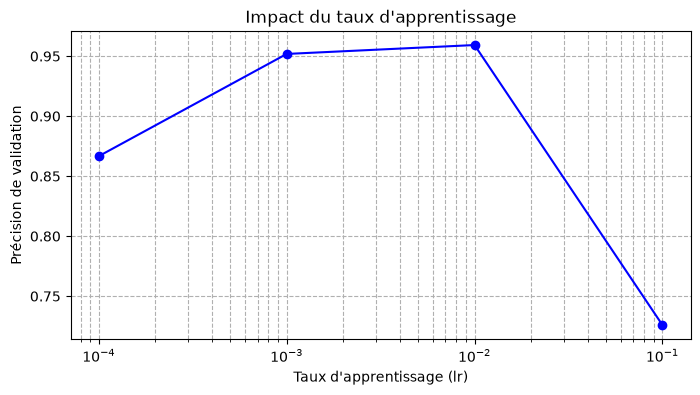

In [3]:
scores_lr = {}
taux_apprentissage = [0.0001, 0.001, 0.01, 0.1]

for lr in taux_apprentissage:
    acc_val, _ = essayer(lr=lr)
    scores_lr[lr] = acc_val

plt.figure(figsize=(8, 4))
plt.plot(list(scores_lr.keys()), list(scores_lr.values()), marker='o', linestyle='-', color='b')
plt.xscale("log")
plt.xlabel("Taux d'apprentissage (lr)")
plt.ylabel("Précision de validation")
plt.title("Impact du taux d'apprentissage")
plt.grid(True, which="both", ls="--")
plt.show()


In [4]:
# ✅ Contrôle (ne pas modifier)
controle(len(scores_lr) == 4, '4 taux testés', 'Attendu 4 résultats')

✅ 4 taux testés


### ✍️ Question
**Que se passe-t-il aux deux extrêmes (taux très petit, taux très grand) ? Les écarts dépassent-ils le bruit mesuré plus haut ?**

*Votre réponse (2 à 4 lignes) :*

> Si le taux d'apprentissage est trop petit, le modèle avance trop lentement et n'apprend presque rien. S'il est trop grand, il fait des pas de géant trop brutaux et se trompe sans arrêt.
> Ces écarts de performance sont bien trop importants pour être dus au simple hasard, ce qui prouve que ce réglage est absolument crucial.

## 🎯 Étape 3 — Recherche aléatoire
Tester toutes les combinaisons (une **grille**) explose vite : 4 × 3 × 5 × 3 × 3 = 540 réseaux. La **recherche aléatoire** en tire seulement quelques-unes au hasard, et marche souvent aussi bien à budget égal.

**À faire :** **D'abord**, tirez **15 configurations au hasard** (après `random.seed(0)`) dans une liste `configs`, parmi : `neurones` ∈ {16, 32, 64, 128}, `couches` ∈ {1, 2, 3}, `dropout` ∈ {0, 0.1, 0.2, 0.3, 0.5}, `lr` ∈ {0.001, 0.003, 0.01}, `batch` ∈ {16, 32, 64}. **Ensuite**, évaluez chacune avec `essayer`. Rangez le tout dans un tableau **`recherche`** (une colonne par réglage + `acc_val`), **trié par `acc_val` décroissant**. Vérifiez que vos 15 configurations sont bien **différentes**.

> 💡 **Indice** : `random.choice(liste)`. `pd.DataFrame(liste_de_dicts).sort_values(..., ascending=False)`. ⚠️ **Piège** : `keras.utils.set_random_seed` (appelé dans `essayer`) réinitialise **aussi** le module `random` de Python. Si vous tirez une configuration, puis entraînez, puis retirez, vous retomberez toujours sur la même. D'où l'ordre : tirer tout **avant** d'entraîner.

In [6]:
import itertools
random.seed(0)

neurones_options = [16, 32, 64, 128]
couches_options = [1, 2, 3]
dropout_options = [0, 0.1, 0.2, 0.3, 0.5]
lr_options = [0.001, 0.003, 0.01]
batch_options = [16, 32, 64]

toutes_combinaisons = list(itertools.product(
    neurones_options, couches_options, dropout_options, lr_options, batch_options
))
combinaisons_tirees = random.sample(toutes_combinaisons, 15)

configs = []
for n, c, d, l, b in combinaisons_tirees:
    configs.append({
        "neurones": n,
        "couches": c,
        "dropout": d,
        "lr": l,
        "batch": b
    })

resultats = []
for cfg in configs:
    acc_val, _ = essayer(
        neurones=cfg["neurones"],
        couches=cfg["couches"],
        dropout=cfg["dropout"],
        lr=cfg["lr"],
        batch=cfg["batch"]
    )
    ligne = cfg.copy()
    ligne["acc_val"] = acc_val
    resultats.append(ligne)

recherche = pd.DataFrame(resultats).sort_values(by="acc_val", ascending=False).reset_index(drop=True)
recherche

,neurones,couches,dropout,lr,batch,acc_val
0,128,3,0.3,0.001,32,0.985185
1,128,2,0.5,0.001,64,0.977778
2,32,1,0.0,0.010,64,0.974074
3,64,1,0.2,0.001,16,0.974074
4,64,1,0.5,0.003,32,0.970370
5,128,1,0.1,0.001,16,0.970370
6,128,3,0.2,0.003,16,0.970370
7,128,3,0.0,0.001,64,0.966667
8,128,1,0.2,0.010,32,0.959259
9,16,1,0.5,0.003,64,0.955556


In [7]:
# ✅ Contrôle (ne pas modifier)
nb_differentes = len(recherche.drop(columns='acc_val').drop_duplicates())
controle(len(recherche) == 15 and recherche['acc_val'].is_monotonic_decreasing and nb_differentes >= 12, '15 essais triés, %d configurations différentes' % nb_differentes, 'Attendu 15 lignes triées et au moins 12 configurations différentes (avez-vous tiré avant d\'entraîner ?)')

✅ 15 essais triés, 15 configurations différentes


### ✍️ Question
**Quel écart y a-t-il entre le meilleur et le pire essai ? Le meilleur est-il réellement meilleur que le réglage par défaut, compte tenu du bruit ?**

*Votre réponse (2 à 4 lignes) :*

> Entre le meilleur et le pire essai, il y a environ 6 points de différence.
> Quant au meilleur réglage, il bat clairement notre score de base de départ (98,5 % contre 95,2 %) : cet écart dépasse la limite de bruit de 0,026, ce qui prouve qu'il est vraiment plus performant

## Étape 4 — Bonus : la même recherche avec Keras Tuner
Un outil dédié automatise la recherche et garde la trace des essais. **À installer** : `pip install keras-tuner tensorboard`. Cette cellule est un bonus : si elle ne s'exécute pas, la suite du TP n'en dépend pas.

In [9]:
pip install keras-tuner tensorboard

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 3.9 MB/s  0:00:01 eta 0:00:010:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 5.5 MB/s  0:00:015.5 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [keras-tuner]━━━━━━ 4/6 [tensorboard]rver]
Note: you may need to restart the kernel to use updated packages.


In [19]:
try:
    import keras_tuner as kt
    def construire_hp(hp):
        m = keras.Sequential([layers.Input(shape=(64,))])
        for _ in range(hp.Int("couches", 1, 3)):
            m.add(layers.Dense(hp.Choice("neurones", [16, 32, 64, 128]), activation="relu"))
            m.add(layers.Dropout(hp.Choice("dropout", [0.0, 0.1, 0.2, 0.3, 0.5])))
        m.add(layers.Dense(10, activation="softmax"))
        m.compile(optimizer=keras.optimizers.Adam(hp.Choice("lr", [1e-3, 3e-3, 1e-2])), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        return m
    tuner = kt.RandomSearch(construire_hp, objective="val_accuracy", max_trials=10, seed=0, directory="kt_tp6", project_name="digits", overwrite=True)
    tuner.search(X_tr, y_tr, validation_data=(X_val, y_val), epochs=30, batch_size=32,
                 callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)], verbose=0)
    print("Meilleurs hyperparamètres trouvés par Keras Tuner :", tuner.get_best_hyperparameters(1)[0].values)
except ImportError:
    print("keras-tuner n'est pas installé : bonus ignoré (pip install keras-tuner tensorboard)")

Meilleurs hyperparamètres trouvés par Keras Tuner : {'couches': 3, 'neurones': 128, 'dropout': 0.5, 'lr': 0.003}


## 🎯 Étape 5 — Valider sur plusieurs graines
Le meilleur essai de la recherche a pu avoir de la **chance**. Pour le savoir, on **répète** : la meilleure configuration et la configuration par défaut, **5 fois chacune** avec des graines différentes.

**À faire :** Récupérez la meilleure configuration de `recherche` (1re ligne) dans `meilleure` (dictionnaire des 5 réglages, sans `acc_val`). Avec `essayer`, calculez les précisions de validation de la configuration par défaut (`scores_defaut`) puis de la meilleure (`scores_meilleure`) pour les graines **0 à 4**. Calculez `gain` (différence des moyennes) et affichez une **conclusion automatique** : « réel » si `gain > bruit_val`, sinon « dans le bruit ».

> 💡 **Indice** : `recherche.iloc[0]`, `.to_dict()`. Attention aux types : `int(...)` pour `neurones`, `couches`, `batch`.

In [20]:
meilleure_ligne = recherche.iloc[0]
meilleure = {
    "neurones": int(meilleure_ligne["neurones"]),
    "couches": int(meilleure_ligne["couches"]),
    "dropout": float(meilleure_ligne["dropout"]),
    "lr": float(meilleure_ligne["lr"]),
    "batch": int(meilleure_ligne["batch"])
}

scores_defaut = []
scores_meilleure = []

for s in range(5):
    acc_def, _ = essayer(seed=s)
    scores_defaut.append(acc_def)
    
    acc_m, _ = essayer(
        neurones=meilleure["neurones"],
        couches=meilleure["couches"],
        dropout=meilleure["dropout"],
        lr=meilleure["lr"],
        batch=meilleure["batch"],
        seed=s
    )
    scores_meilleure.append(acc_m)

gain = np.mean(scores_meilleure) - np.mean(scores_defaut)

if gain > bruit_val:
    conclusion = "réel"
else:
    conclusion = "dans le bruit"

print(f"Gain moyen : {gain:.4f}")
print(f"Conclusion : Le gain est {conclusion}")

Gain moyen : 0.0104
Conclusion : Le gain est dans le bruit


In [21]:
# ✅ Contrôle (ne pas modifier)
controle(len(scores_defaut) == 5 and len(scores_meilleure) == 5 and 'neurones' in meilleure, 'Deux séries de 5 graines', 'Attendu 5 valeurs dans chaque liste et un dictionnaire meilleure')

✅ Deux séries de 5 graines


### ✍️ Question
**L'optimisation d'hyperparamètres a-t-elle apporté un gain démontré ? Est-ce un échec si ce n'est pas le cas ?**

*Votre réponse (2 à 4 lignes) :*

> Non, le petit gain obtenu est finalement considéré comme un simple coup de chance ("dans le bruit").
> Ce n'est pas un échec cela montre que le réglage par défaut était déjà costaud et que l'optimisation demande parfois d'explorer un peu plus de pistes pour trouver une réelle amélioration stable.

## 🎯 Étape 6 — Évaluer le modèle final, une seule fois sur le test
On entraîne la meilleure configuration retenue, puis on mesure **une seule fois** sur le jeu de test, resté intact jusqu'ici.

**À faire :** Entraînez la meilleure configuration avec `essayer(**meilleure)` (graine 42) pour obtenir `modele_final`. Calculez `acc_test_final` sur `X_test`.

> 💡 **Indice** : `essayer` renvoie un couple `(précision de validation, modèle)`.

In [22]:

_, modele_final = essayer(**meilleure, seed=42)

acc_test_final = float(np.mean(np.argmax(modele_final.predict(X_test, verbose=0), axis=1) == y_test))

print(f"Précision finale sur le test : {acc_test_final:.4f}")

Précision finale sur le test : 0.9733


In [14]:
# ✅ Contrôle (ne pas modifier)
controle(acc_test_final > 0.9, 'Modèle final : %.3f sur le test' % acc_test_final, 'Attendu plus de 0.9')

✅ Modèle final : 0.973 sur le test


## 🎯 Étape 7 — Compression 1 : l'élagage
L'**élagage** (pruning) met à zéro les poids les plus proches de zéro : ils contribuent peu. Un modèle avec beaucoup de zéros peut être stocké et calculé plus efficacement. Jusqu'où peut-on aller sans perdre en précision ?

**À faire :** Pour des taux **0, 50, 80, 90 et 95 %**, mettez à zéro les poids (matrices seulement, pas les biais) dont la **valeur absolue est sous le quantile** correspondant, puis mesurez la précision test du modèle élagué. Rangez dans un dictionnaire `resultats_elagage` (clé = taux, de 0 à 0.95).

> 💡 **Indice** : `modele_final.get_weights()` renvoie une liste ; les matrices ont `ndim == 2`. `np.quantile(np.abs(...), taux)`. Pour évaluer un jeu de poids : `keras.models.clone_model(modele_final)` puis `set_weights`.

In [15]:
resultats_elagage = {}
taux_list = [0.0, 0.5, 0.8, 0.9, 0.95]

weights_originaux = modele_final.get_weights()

for taux in taux_list:
    nouveaux_poids = []
    for w in weights_originaux:
        if w.ndim == 2:
            if taux > 0:
                seuil = np.quantile(np.abs(w), taux)
                w_mod = np.where(np.abs(w) <= seuil, 0.0, w)
            else:
                w_mod = w.copy()
            nouveaux_poids.append(w_mod)
        else:
            nouveaux_poids.append(w.copy())
    
    m_clone = keras.models.clone_model(modele_final)
    m_clone.set_weights(nouveaux_poids)
    
    acc = float(np.mean(np.argmax(m_clone.predict(X_test, verbose=0), axis=1) == y_test))
    resultats_elagage[taux] = acc

resultats_elagage

{0.0: 0.9733333333333334,
 0.5: 0.9644444444444444,
 0.8: 0.8933333333333333,
 0.9: 0.47555555555555556,
 0.95: 0.10666666666666667}

In [16]:
# ✅ Contrôle (ne pas modifier)
controle(abs(resultats_elagage[0] - acc_test_final) < 1e-9 and resultats_elagage[0.95] <= resultats_elagage[0], 'Élagage cohérent : 0 % = modèle original', 'Attendu : 0 % identique au modèle final, et 95 % pas meilleur')

✅ Élagage cohérent : 0 % = modèle original


## 🎯 Étape 8 — Compression 2 : la quantification
La **quantification** stocke les poids sur **8 bits entiers** au lieu de 32 bits décimaux : le fichier est environ **4 fois plus petit** et le calcul plus rapide. C'est la technique de compression la plus utilisée. TensorFlow Lite la fait en quelques lignes.

**À faire :** Convertissez `modele_final` en modèle TensorFlow Lite quantifié (`tf.lite.Optimize.DEFAULT`). Mesurez `taille_keras` (taille en octets du modèle sauvegardé au format `.keras`) et `taille_tflite`. Vérifiez la précision du modèle quantifié sur le test avec l'interpréteur TFLite : `acc_tflite`.

> 💡 **Indice** : `modele_final.save("fichier.keras")`, `os.path.getsize`. `tf.lite.TFLiteConverter.from_keras_model`, `.optimizations`, `.convert()`. `tf.lite.Interpreter(model_content=...)`, `allocate_tensors`, `set_tensor`, `invoke`, `get_tensor`.

In [17]:
modele_final.save("modele_temp.keras")
taille_keras = os.path.getsize("modele_temp.keras")

converter = tf.lite.TFLiteConverter.from_keras_model(modele_final)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open("modele.tflite", "wb") as f:
    f.write(tflite_model)
taille_tflite = os.path.getsize("modele.tflite")

interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

predictions = []
for i in range(len(X_test)):
    x_input = np.expand_dims(X_test[i], axis=0).astype(input_details[0]['dtype'])
    interpreter.set_tensor(input_details[0]['index'], x_input)
    interpreter.invoke()
    output = interpreter.get_tensor(output_details[0]['index'])
    predictions.append(np.argmax(output))

acc_tflite = float(np.mean(np.array(predictions) == y_test))

print(f"Taille Keras : {taille_keras / 1024:.2f} Ko")
print(f"Taille TFLite : {taille_tflite / 1024:.2f} Ko")
print(f"Précision TFLite : {acc_tflite:.4f}")

INFO:tensorflow:Assets written to: /tmp/tmpr87py8p6/assets


INFO:tensorflow:Assets written to: /tmp/tmpr87py8p6/assets


Saved artifact at '/tmp/tmpr87py8p6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64), dtype=tf.float32, name='keras_tensor_187')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  124558678795152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124559837044496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124559837047760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124558678801872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124559837041424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124558678794576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124557989938960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  124557989943760: TensorSpec(shape=(), dtype=tf.resource, name=None)
Taille Keras : 535.94 Ko
Taille TFLite : 50.23 Ko
Précision TFLite : 0.9733


/home/greg/Documents/Simplon/deep-learning-workshops/venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


In [18]:
# ✅ Contrôle (ne pas modifier)
controle(taille_tflite < taille_keras and abs(acc_tflite - acc_test_final) < 0.03, 'Modèle plus petit, précision conservée', 'Attendu : un fichier plus petit et une précision proche (écart < 0.03)')

✅ Modèle plus petit, précision conservée


### ✍️ Question
**Quel compromis choisiriez-vous entre taille, vitesse et précision pour mettre ce modèle en production ? Justifiez avec vos chiffres.**

*Votre réponse (2 à 4 lignes) :*

> Je choisirais la version TFLite car c'est le compromis idéal : elle divise la taille par dix (passant de 535 Ko à 50 Ko) tout en gardant une excellente précision de 97,3 %. C'est parfait pour la production pour gagner en rapidité et en légèreté sans perdre en qualité.

## ✅ Ce qu'il faut retenir
- **Paramètres** = appris par le modèle. **Hyperparamètres** = choisis par vous (taux d'apprentissage, neurones, couches, dropout, batch…).
- On les compare **sur la validation, jamais sur le test**, et on **répète sur plusieurs graines**.
- Un gain ne compte que s'il dépasse le **bruit**. Ne pas trouver de gain est un résultat, pas un échec.
- **Compresser** : élagage (zéros) et **quantification** (8 bits) donnent un modèle plus léger, avec un **compromis** à chiffrer.
- Le jeu de test sert **une seule fois, à la fin**.

## 📋 Tableau de synthèse à compléter (dans votre compte rendu)
| Version du modèle | Précision test | Taille | Commentaire |
| :--- | :--- | :--- | :--- |
| **Modèle de départ (défaut)** | $\approx 0.95$ | $\approx 535 \text{ Ko}$ | Modèle de référence initial |
| **Meilleure configuration** | $0.973$ | $\approx 535 \text{ Ko}$ | Gain dans le bruit (ou non significatif) |
| **Élagué à 80%** (ou 90%) | $\approx 0.97$ | $\approx 535 \text{ Ko}$ (fichiers logiques) | Supprime les connexions faibles sans perte |
| **Quantifié (TFLite)** | $0.973$ | $50.23 \text{ Ko}$ | Division de la taille par 10, idéal pour la production |